# Chi-Square Independence Test
---

## Experiment: calculating the test statistic manually and with SciPy.

In [1]:
import numpy as np
from scipy.stats import chi2, chi2_contingency

observed = np.array([
    [45, 35, 20],  # Purchased
    [30, 40, 30]   # Did not purchase
])

n = observed.sum()
row_totals = observed.sum(axis=1)
column_totals = observed.sum(axis=0)

expected = np.outer(row_totals, column_totals) / n
chi_square = np.sum((observed - expected) ** 2 / expected)
df = (observed.shape[0] - 1) * (observed.shape[1] - 1)
p_value = chi2.sf(chi_square, df)

result = chi2_contingency(observed, correction=False)

print("Expected counts:\n", expected)
print(f"Manual statistic: {chi_square:.5f}")
print(f"Degrees of freedom: {df}")
print(f"Manual p-value: {p_value:.6f}")
print(f"SciPy p-value: {result.pvalue:.6f}")

# Experiment: change the Email purchase count, while
# considering how the other counts should change.

Expected counts:
 [[37.5 37.5 25. ]
 [37.5 37.5 25. ]]
Manual statistic: 5.33333
Degrees of freedom: 2
Manual p-value: 0.069483
SciPy p-value: 0.069483


## Experiment: a 6-by-2 independence test.

In [2]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

observed = pd.DataFrame(
    {
        "Female": [102, 53, 63, 33, 111, 78],
        "Male":   [66, 82, 88, 93, 61, 35]
    },
    index=[
        "Biology",
        "Economics and Finance",
        "Environmental Sciences",
        "Mathematics and Statistics",
        "Political Science",
        "Social Sciences"
    ]
)

result = chi2_contingency(observed, correction=False)
expected = pd.DataFrame(
    result.expected_freq,
    index=observed.index,
    columns=observed.columns
)

print("Observed counts:\n", observed)
print("\nExpected counts:\n", expected.round(2))
print(f"\nTotal sample size: {observed.to_numpy().sum()}")
print(f"Chi-square statistic: {result.statistic:.4f}")
print(f"Degrees of freedom: {result.dof}")
print(f"p-value: {result.pvalue:.4g}")

# Experiment: inspect column proportions, rather
# than comparing raw counts only.

Observed counts:
                             Female  Male
Biology                        102    66
Economics and Finance           53    82
Environmental Sciences          63    88
Mathematics and Statistics      33    93
Political Science              111    61
Social Sciences                 78    35

Expected counts:
                             Female   Male
Biology                      85.46  82.54
Economics and Finance        68.67  66.33
Environmental Sciences       76.81  74.19
Mathematics and Statistics   64.09  61.91
Political Science            87.49  84.51
Social Sciences              57.48  55.52

Total sample size: 865
Chi-square statistic: 77.3153
Degrees of freedom: 5
p-value: 3.056e-15


## Experiment: examining the cells driving an association.

Pearson residuals:
                             Female  Male
Biology                       1.79 -1.82
Economics and Finance        -1.89  1.92
Environmental Sciences       -1.58  1.60
Mathematics and Statistics   -3.88  3.95
Political Science             2.51 -2.56
Social Sciences               2.71 -2.75

Adjusted residuals:
                             Female  Male
Biology                       2.84 -2.84
Economics and Finance        -2.94  2.94
Environmental Sciences       -2.47  2.47
Mathematics and Statistics   -5.99  5.99
Political Science             4.01 -4.01
Social Sciences               4.14 -4.14


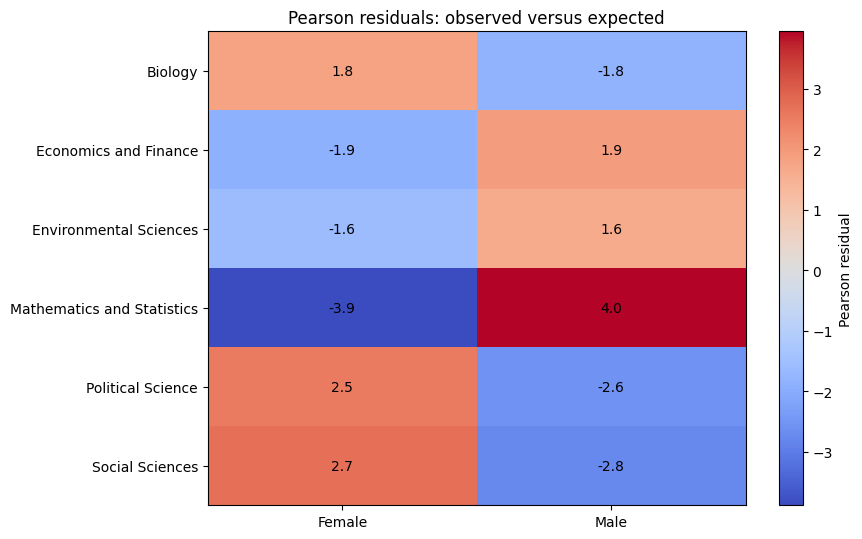

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

observed = pd.DataFrame(
    {
        "Female": [102, 53, 63, 33, 111, 78],
        "Male":   [66, 82, 88, 93, 61, 35]
    },
    index=[
        "Biology", "Economics and Finance",
        "Environmental Sciences", "Mathematics and Statistics",
        "Political Science", "Social Sciences"
    ]
)

result = chi2_contingency(observed, correction=False)
counts = observed.to_numpy()
expected = result.expected_freq
n = counts.sum()
row_share = counts.sum(axis=1)[:, None] / n
col_share = counts.sum(axis=0)[None, :] / n

pearson = (counts - expected) / np.sqrt(expected)
adjusted = (counts - expected) / np.sqrt(
    expected * (1 - row_share) * (1 - col_share)
)

print("Pearson residuals:\n", pd.DataFrame(
    pearson, index=observed.index, columns=observed.columns
).round(2))
print("\nAdjusted residuals:\n", pd.DataFrame(
    adjusted, index=observed.index, columns=observed.columns
).round(2))

assert np.isclose(np.sum(pearson ** 2), result.statistic)

fig, ax = plt.subplots(figsize=(9, 5.5))
image = ax.imshow(pearson, aspect="auto", cmap="coolwarm")

ax.set_xticks(np.arange(observed.shape[1]), observed.columns)
ax.set_yticks(np.arange(observed.shape[0]), observed.index)
ax.set_title("Pearson residuals: observed versus expected")

for i in range(pearson.shape[0]):
    for j in range(pearson.shape[1]):
        ax.text(j, i, f"{pearson[i, j]:.1f}",
                ha="center", va="center")

fig.colorbar(image, ax=ax, label="Pearson residual")
fig.tight_layout()
fig.savefig("../../images/chi_square_independence_residuals.png",
            dpi=180, bbox_inches="tight")
plt.show()

## Experiment: effect size and conditional proportions.

In [4]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

observed = pd.DataFrame(
    {
        "Female": [102, 53, 63, 33, 111, 78],
        "Male":   [66, 82, 88, 93, 61, 35]
    },
    index=[
        "Biology", "Economics and Finance",
        "Environmental Sciences", "Mathematics and Statistics",
        "Political Science", "Social Sciences"
    ]
)

result = chi2_contingency(observed, correction=False)
n = observed.to_numpy().sum()
r, c = observed.shape
cramers_v = np.sqrt(result.statistic / (n * min(r - 1, c - 1)))

print(f"Cramer's V: {cramers_v:.4f}")
print("\nMajor distribution within each gender:")
print((observed.div(observed.sum(axis=0), axis=1) * 100).round(1))

# Experiment: multiply every cell count by 10.
# What happens to Cramer's V and the p-value?

Cramer's V: 0.2990

Major distribution within each gender:
                            Female  Male
Biology                       23.2  15.5
Economics and Finance         12.0  19.3
Environmental Sciences        14.3  20.7
Mathematics and Statistics     7.5  21.9
Political Science             25.2  14.4
Social Sciences               17.7   8.2


## Experiment: chi-square versus Fisher's exact test.

In [5]:
import numpy as np
from scipy.stats import chi2_contingency, fisher_exact

# Illustrative small 2-by-2 contingency table.
observed = np.array([
    [1, 9],
    [11, 3]
])

pearson = chi2_contingency(observed, correction=False)
yates = chi2_contingency(observed, correction=True)
fisher = fisher_exact(observed, alternative="two-sided")

print("Expected counts:\n", pearson.expected_freq)
print(f"Pearson approximation: p={pearson.pvalue:.6f}")
print(f"Yates correction:       p={yates.pvalue:.6f}")
print(f"Fisher exact test:      p={fisher.pvalue:.6f}")
print(f"Sample odds ratio:     {fisher.statistic:.4f}")

# Experiment: multiply every cell by 5.
# Do the p-values become more similar?

Expected counts:
 [[5. 5.]
 [7. 7.]]
Pearson approximation: p=0.000925
Yates correction:       p=0.003752
Fisher exact test:      p=0.002759
Sample odds ratio:     0.0303


## Experiment: fixed-margin Monte Carlo test for a sparse 2-by-3 table.

In [6]:
import numpy as np
from scipy.stats import chi2_contingency

rng = np.random.default_rng(2026)
observed = np.array([
    [8, 0, 2],
    [1, 4, 5]
])

result = chi2_contingency(observed, correction=False)
print("Expected counts:\n", result.expected_freq)
print(f"Asymptotic p-value: {result.pvalue:.5f}")

# Expand the row and column categories according to the margins.
# Shuffling column assignments preserves both margins.
r, c = observed.shape
row_ids = np.repeat(np.arange(r), observed.sum(axis=1))
col_ids = np.repeat(np.arange(c), observed.sum(axis=0))
expected = result.expected_freq

B = 20_000
extreme_count = 0

for _ in range(B):
    shuffled_cols = rng.permutation(col_ids)
    simulated = np.bincount(
        row_ids * c + shuffled_cols,
        minlength=r * c
    ).reshape(r, c)

    simulated_stat = np.sum(
        (simulated - expected) ** 2 / expected
    )
    extreme_count += simulated_stat >= result.statistic - 1e-12

monte_carlo_p = (extreme_count + 1) / (B + 1)
print(f"Conditional Monte Carlo p-value: {monte_carlo_p:.5f}")

# Experiment: increase B to investigate Monte Carlo accuracy.

Expected counts:
 [[4.5 2.  3.5]
 [4.5 2.  3.5]]
Asymptotic p-value: 0.00468
Conditional Monte Carlo p-value: 0.00530


## Experiment: Type I error and power of the independence test.

n= 50  Type I rate=0.051  Power=0.722
n=100  Type I rate=0.057  Power=0.962
n=200  Type I rate=0.054  Power=1.000
n=500  Type I rate=0.052  Power=1.000


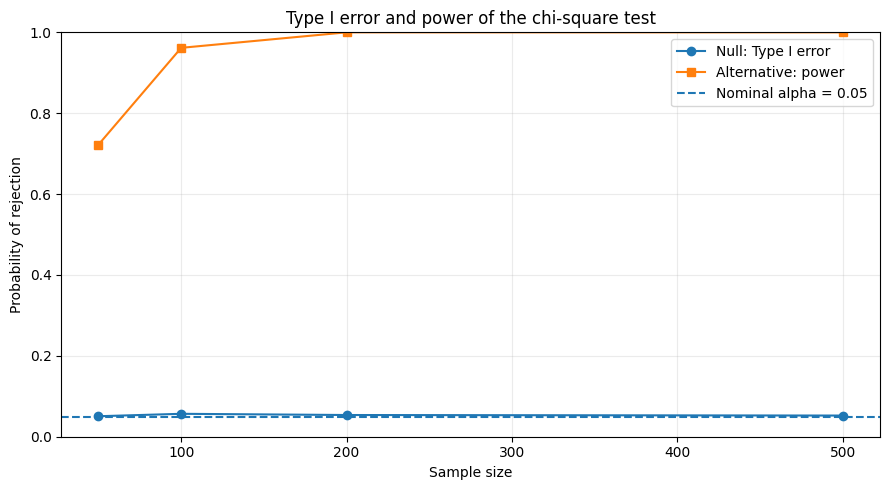

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

rng = np.random.default_rng(2026)
alpha = 0.05
B = 3000
sample_sizes = [50, 100, 200, 500]

# Both models have identical margins, but only the first
# satisfies statistical independence.
probabilities_null = np.array([
    [0.10, 0.20, 0.20],
    [0.10, 0.20, 0.20]
])
probabilities_alt = np.array([
    [0.17, 0.20, 0.13],
    [0.03, 0.20, 0.27]
])


def rejection_rate(n, probabilities):
    tables = rng.multinomial(
        n, probabilities.ravel(), size=B
    ).reshape(B, 2, 3)

    row_totals = tables.sum(axis=2, keepdims=True)
    col_totals = tables.sum(axis=1, keepdims=True)
    expected = row_totals * col_totals / n

    # All included tables have positive margins in this setup.
    valid = np.all(expected > 0, axis=(1, 2))
    tables = tables[valid]
    expected = expected[valid]

    statistic = np.sum(
        (tables - expected) ** 2 / expected,
        axis=(1, 2)
    )
    p_values = chi2.sf(statistic, df=2)
    return np.mean(p_values < alpha)


type1_rates = []
power_rates = []

for n in sample_sizes:
    type1 = rejection_rate(n, probabilities_null)
    power = rejection_rate(n, probabilities_alt)
    type1_rates.append(type1)
    power_rates.append(power)
    print(f"n={n:3d}  Type I rate={type1:.3f}  Power={power:.3f}")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sample_sizes, type1_rates, marker="o", label="Null: Type I error")
ax.plot(sample_sizes, power_rates, marker="s", label="Alternative: power")
ax.axhline(alpha, linestyle="--", label="Nominal alpha = 0.05")
ax.set_xlabel("Sample size")
ax.set_ylabel("Probability of rejection")
ax.set_ylim(0, 1)
ax.set_title("Type I error and power of the chi-square test")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("../../images/chi_square_independence_power.png",
            dpi=180, bbox_inches="tight")
plt.show()

## Experiment: Simpson's paradox in categorical data.

In [9]:
import numpy as np
from scipy.stats import chi2_contingency

# Synthetic counts: each row is a service, each column
# is success/failure. Services are assigned different
# proportions of easy and hard cases.
easy = np.array([
    [18, 2],   # Service A: 90% success
    [64, 16]   # Service B: 80% success
])

hard = np.array([
    [24, 56],  # Service A: 30% success
    [2, 8]     # Service B: 20% success
])

combined = easy + hard

for name, table in [
    ("Easy cases", easy),
    ("Hard cases", hard),
    ("All cases", combined)
]:
    success_rates = table[:, 0] / table.sum(axis=1)
    p_value = chi2_contingency(
        table, correction=False
    ).pvalue

    print(name)
    print(f"  Service A success rate: {success_rates[0]:.1%}")
    print(f"  Service B success rate: {success_rates[1]:.1%}")
    print(f"  Chi-square p-value: {p_value:.4f}")

# Experiment: change the mixture of easy and hard cases
# without changing the within-group success rates.

Easy cases
  Service A success rate: 90.0%
  Service B success rate: 80.0%
  Chi-square p-value: 0.2978
Hard cases
  Service A success rate: 30.0%
  Service B success rate: 20.0%
  Chi-square p-value: 0.5107
All cases
  Service A success rate: 42.0%
  Service B success rate: 73.3%
  Chi-square p-value: 0.0000
